# NGC4654 bivariate Local Moran maps

The inputs are the [Paper II SFR excess map](20261117_NGC4654_SFR_excess_Fourier_VIVA.ipynb) and the [SFH16 stellar mass surface-density map](20261117_NGC4654_stellar_mass_Fourier_VIVA.ipynb). The SFR excess \(E\) is the log SFR surface-density residual relative to the pre-peak rSFMS, divided by its width \(W\). On the shared finite footprint, divide the FITS \(\log_{10}\Sigma_\star\) values into 12 equal-width intervals spanning their observed range. Subtract the mean log density of the spaxels in each interval to get \(\Delta\log_{10}\Sigma_\star\) in dex. Use the existing \(E\) values for SFR.

The calculation follows [Moran_MAUVE_EW](20260608_Moran_MAUVE_EW.ipynb). On the common finite footprint, average each field within each continuum BINID and standardize the bin means across the galaxy using equal bin weights. Two distinct BINIDs are neighbours when any of their common-footprint pixels touch by an edge or corner (queen adjacency). Each unique neighbour has equal weight. Isolated bins have undefined local scores. The score is assigned back to common-footprint pixels of its bin.

$$
I_i^{E,\Delta\star}=z_{E,i}\,\overline{z_{\Delta\star}}_{\mathcal N_i},
\qquad
I_i^{\Delta\star,E}=z_{\Delta\star,i}\,\overline{z_E}_{\mathcal N_i}.
$$

The two directions compare SFR excess here with stellar mass residuals nearby, and stellar mass residuals here with SFR excess nearby. Positive values pair departures of the same sign, and negative values pair departures of opposite signs. Zero refers to the mean of each field across the shared continuum bins after standardization. The score is descriptive. The colour transition at \(|I_i|=1\) follows Moran_MAUVE and does not define statistical significance.

The upper panels show \(E\) on its original SF footprint and the mass residual on the shared footprint. The lower panels use the overlap across the full observed field, without the Fourier fit's radial cut. Run from top to bottom to reproduce the reference calibration and the maps without running the angular fits.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound

N_MASS_INTERVALS = 12
DELTA_MASS_LABEL = r'$\Delta\log_{10}\Sigma_\star$ (dex)'


Matplotlib is building the font cache; this may take a moment.


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    gas_arrays['LOGSFR_SURFACE_DENSITY_HII'] += delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


In [3]:
# Only load the pre-peak reference sample and the NGC4654 target.
def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        if all(geometry_by_galaxy.loc[g, 'stage_code'] != 1 and g != 'NGC4654' for g in components):
            continue
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            if component.stage_code != 1 and galaxy != 'NGC4654':
                continue
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths

sf_x_parts, sf_y_parts, sf_group_parts, sf_error_parts = [], [], [], []
inventory_rows, count_rows = [], []
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,product_id=product_id,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))
    if not meta['inclination_ok'] or missing:
        continue
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    assert not np.any(sf & ~balmer), f'{gal}: SF overlaps Balmer ND'
    group_id = len(count_rows)
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    sf_group_parts.append(np.full(int(sf.sum()), group_id, dtype=np.int16))
    if gal == 'NGC4654':
        target_sf = sf
        target_binid, binid_header = read_map(paths['mass'], 'BINID')
        if target_binid.shape != mass.shape:
            raise ValueError('NGC4654: continuum BINID and mass shapes differ')
        check_wcs(mass_hdr, binid_header, mass.shape, 'NGC4654 mass/continuum BINID')
        native_bin = (np.isfinite(target_binid) & (target_binid >= 0)
                      & (target_binid == np.floor(target_binid)))
        stellar_usable = native_bin & np.isfinite(mass) & (spatial_mask == 0) & snr_pass
        target_mass_map = np.where(stellar_usable, mass, np.nan)
        target_mass_header = mass_hdr.copy()
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
                           usable=int(valid.sum()), SF=int(sf.sum())))

if not count_rows:
    raise RuntimeError('No complete Paper II product sets found for NGC4654 or the pre-peak reference')
inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
sf_x, sf_y, sf_group = (np.concatenate(parts) for parts in (sf_x_parts, sf_y_parts, sf_group_parts))
assert sf_x.size == sf_y.size == sf_group.size == counts.SF.sum()
display(inventory[['galaxy', 'product_id', 'stage', 'inclination', 'status']])
display(counts)

,galaxy,product_id,stage,inclination,status
0,NGC4189,NGC4189,1,42.0,included
1,NGC4192,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
2,NGC4222,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
3,NGC4254,NGC4254,1,39.0,included
4,NGC4294,NGC4294,1,74.0,included
5,NGC4321,NGC4321,1,32.0,included
6,NGC4351,NGC4351,1,48.0,included
7,NGC4383,NGC4383,1,56.0,included
8,NGC4396,NGC4396,1,83.0,excluded: inclination >=80 or unavailable
9,NGC4535,NGC4535,1,48.0,included


,galaxy,stage,inclination,usable,SF
0,NGC4189,1,42.0,134346,88582
1,NGC4254,1,39.0,615883,453580
2,NGC4294,1,74.0,125185,66537
3,NGC4321,1,32.0,808599,382821
4,NGC4351,1,48.0,98128,29767
5,NGC4383,1,56.0,62174,15627
6,NGC4535,1,48.0,459337,161648
7,NGC4567,1,49.0,175337,87590
8,NGC4568,1,70.0,218439,114364
9,NGC4654,2,61.0,555079,325678


In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])

sf_stage = counts.stage.to_numpy(int)[sf_group]
assert (sf_stage == 1).any(), 'No pre-peak SF reference products'
pre=sf_stage==1
pre_peak_fit=equal_galaxy_ols(sf_x[pre],sf_y[pre],sf_group[pre])

assert counts.inclination.lt(INCLINATION_MAX).all()
excess_meta = counts.reset_index(drop=True)
target = excess_meta.loc[excess_meta.galaxy.eq('NGC4654')]
if len(target) != 1 or int(target.iloc[0].SF) == 0:
    raise ValueError('NGC4654: not available with SF spaxels after the global cuts; inspect inventory')
assert int(target.iloc[0].stage) == 2, 'NGC4654: unexpected catalogue stage'
excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width

display(excess_width_by_galaxy)
print(f'Pre-peak equal-galaxy reference: y={pre_peak_fit["slope"]:.6f}x{pre_peak_fit["intercept"]:+.6f}; W={excess_width:.6f} dex')

,galaxy,N_width,width_dex,fraction_clipped_to_zero
0,NGC4189,88582,0.359797,0.027974
1,NGC4254,453580,0.447343,0.028438
2,NGC4294,66537,0.357248,0.014188
3,NGC4321,382821,0.389444,0.029442
4,NGC4351,29767,0.366184,0.017402
5,NGC4383,15627,0.444388,0.018878
6,NGC4535,161648,0.464960,0.016307
7,NGC4567,87590,0.335900,0.039034
8,NGC4568,114364,0.358164,0.042076


Pre-peak equal-galaxy reference: y=0.748260x-7.992286; W=0.391492 dex


In [5]:
target_group = int(excess_meta.index[excess_meta.galaxy.eq('NGC4654')].item())
target_excess = excess_values[sf_group == target_group]
assert target_excess.size == target_sf.sum()
sfr_excess_map = np.full(target_sf.shape, np.nan)
sfr_excess_map[target_sf] = target_excess
joint = np.isfinite(sfr_excess_map) & np.isfinite(target_mass_map)
if not joint.any():
    raise ValueError('No common finite spaxels for SFR excess and stellar mass density')

# Define mass intervals from the joint spaxels, with the maximum in the last interval.
joint_mass = target_mass_map[joint]
if joint_mass.min() == joint_mass.max():
    raise ValueError('Stellar mass density is constant over the common footprint')
mass_edges = np.linspace(joint_mass.min(), joint_mass.max(), N_MASS_INTERVALS + 1)
mass_interval = np.searchsorted(mass_edges[1:-1], joint_mass, side='right')
mass_interval_count = np.bincount(mass_interval, minlength=N_MASS_INTERVALS)
mass_interval_total = np.bincount(mass_interval, weights=joint_mass, minlength=N_MASS_INTERVALS)
mass_interval_mean = np.divide(
    mass_interval_total, mass_interval_count, out=np.full(N_MASS_INTERVALS, np.nan),
    where=mass_interval_count > 0)
delta_mass_map = np.full(target_sf.shape, np.nan)
delta_mass_map[joint] = joint_mass - mass_interval_mean[mass_interval]
display(pd.DataFrame({
    'log mass lower': mass_edges[:-1],
    'log mass upper': mass_edges[1:],
    'N_spaxels': mass_interval_count,
    'mean log mass': mass_interval_mean,
}).rename_axis('Mass interval').round(5))


,log mass lower,log mass upper,N_spaxels,mean log mass
Mass interval,,,,
0,6.56283,6.78913,1891,6.71467
1,6.78913,7.01544,12407,6.92010
2,7.01544,7.24174,30427,7.14812
3,7.24174,7.46804,58838,7.36024
4,7.46804,7.69435,60807,7.57927
5,7.69435,7.92065,58512,7.80526
6,7.92065,8.14695,50361,8.02706
7,8.14695,8.37326,30772,8.24823
8,8.37326,8.59956,14815,8.47115


In [6]:
from scipy.sparse import csr_matrix

# Compact indices for valid continuum bins. -1 marks pixels outside the overlap.
bin_ids, inverse, counts_per_bin = np.unique(
    target_binid[joint].astype(np.int64), return_inverse=True, return_counts=True)
node_map = np.full(joint.shape, -1, dtype=np.int64)
node_map[joint] = inverse
n_bins = len(bin_ids)

values = np.column_stack([
    np.bincount(inverse, weights=field[joint], minlength=n_bins) / counts_per_bin
    for field in (sfr_excess_map, delta_mass_map)
])
scale = values.std(axis=0)
if np.any(scale == 0) or not np.isfinite(scale).all():
    raise ValueError('Both input fields must have nonzero finite variance across bins')
z = (values - values.mean(axis=0)) / scale

# Four forward pixel offsets describe queen contacts once per pixel pair.
contacts = []
for left, right in (
    (node_map[:, :-1], node_map[:, 1:]),
    (node_map[:-1, :], node_map[1:, :]),
    (node_map[:-1, :-1], node_map[1:, 1:]),
    (node_map[:-1, 1:], node_map[1:, :-1]),
):
    touch = (left >= 0) & (right >= 0) & (left != right)
    contacts.append(np.column_stack((left[touch], right[touch])))
edges = np.unique(np.sort(np.concatenate(contacts), axis=1), axis=0)
u, v = edges.T
rows, cols = np.r_[u, v], np.r_[v, u]
adjacency = csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(n_bins, n_bins))
degree = np.asarray(adjacency.sum(axis=1)).ravel()
connected = degree > 0
if not connected.any():
    raise ValueError('No touching continuum bins in the shared footprint')
lag = np.full_like(z, np.nan)
lag[connected] = (adjacency @ z)[connected] / degree[connected, None]
local_scores = z * lag[:, ::-1]

sfr_to_delta_mass_map = np.full(joint.shape, np.nan)
delta_mass_to_sfr_map = np.full(joint.shape, np.nan)
sfr_to_delta_mass_map[joint], delta_mass_to_sfr_map[joint] = local_scores[inverse].T

print(f'SFR excess: {np.isfinite(sfr_excess_map).sum():,} spaxels')
print(f'Stellar mass: {np.isfinite(target_mass_map).sum():,} spaxels')
print(f'Shared footprint: {joint.sum():,} spaxels in {n_bins:,} continuum bins')
print(f'Queen graph: {len(edges):,} edges and {(~connected).sum():,} isolated bins')


SFR excess: 325,678 spaxels
Stellar mass: 555,079 spaxels
Shared footprint: 325,678 spaxels in 17,317 continuum bins
Queen graph: 50,892 edges and 42 isolated bins


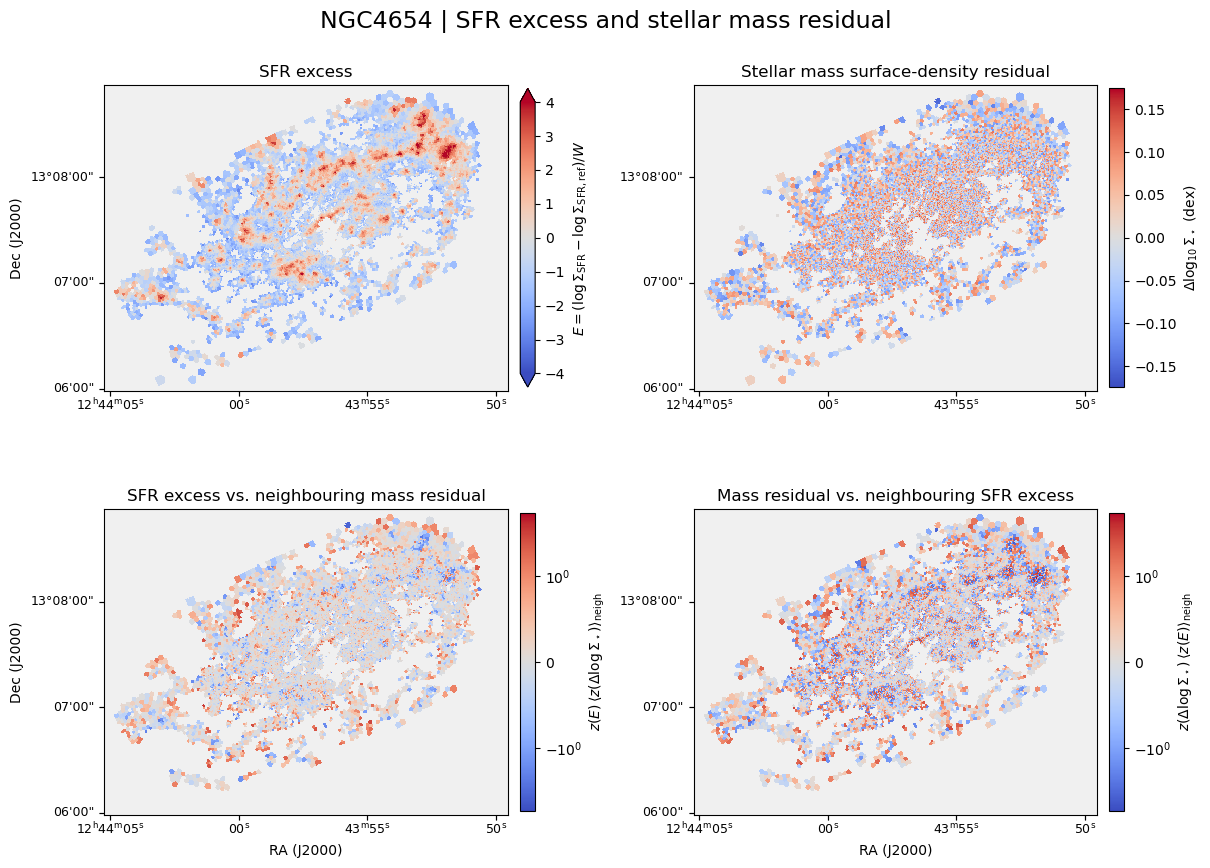

In [7]:
from matplotlib.colors import SymLogNorm

vmax = np.abs(local_scores[connected]).max()
norm = SymLogNorm(linthresh=1.0, vmin=-vmax, vmax=vmax)
delta_limit = np.max(np.abs(delta_mass_map[joint]))
extent_y, extent_x = np.nonzero(np.isfinite(target_mass_map) | np.isfinite(sfr_excess_map))
wcs = WCS(target_mass_header).celestial
fig, axes = plt.subplots(2, 2, figsize=(12, 9), layout='constrained',
                         subplot_kw={'projection': wcs})
panels = (
    (sfr_excess_map, 'SFR excess', r'$E=(\log\Sigma_{\rm SFR}-\log\Sigma_{\rm SFR,ref})/W$',
     dict(cmap='coolwarm', vmin=-4, vmax=4), 'both'),
    (delta_mass_map, 'Stellar mass surface-density residual', DELTA_MASS_LABEL,
     dict(cmap='coolwarm', vmin=-delta_limit, vmax=delta_limit), 'neither'),
    (sfr_to_delta_mass_map, 'SFR excess vs. neighbouring mass residual',
     r'$z(E)\,\langle z(\Delta\log\Sigma_\star)\rangle_{\rm neigh}$',
     dict(cmap='coolwarm', norm=norm), 'neither'),
    (delta_mass_to_sfr_map, 'Mass residual vs. neighbouring SFR excess',
     r'$z(\Delta\log\Sigma_\star)\,\langle z(E)\rangle_{\rm neigh}$',
     dict(cmap='coolwarm', norm=norm), 'neither'),
)
for i, (ax, (field, title, label, style, extend)) in enumerate(zip(axes.flat, panels, strict=True)):
    ax.set_facecolor('0.94')
    im = ax.imshow(field, origin='lower', interpolation='nearest', **style)
    ax.set(xlim=(extent_x.min() - 15, extent_x.max() + 15),
           ylim=(extent_y.min() - 15, extent_y.max() + 15), title=title)
    ra, dec = ax.coords
    ra.set_major_formatter('hh:mm:ss')
    dec.set_major_formatter('dd:mm:ss')
    for coord, side in ((ra, 'b'), (dec, 'l')):
        coord.set_ticks(number=4)
        coord.set_ticks_position(side)
        coord.set_ticklabel_position(side)
        coord.set_ticklabel(size=9, exclude_overlapping=True)
    ra.set_axislabel('RA (J2000)' if i >= 2 else '')
    dec.set_axislabel('Dec (J2000)' if i % 2 == 0 else '')
    cbar = fig.colorbar(im, ax=ax, label=label, shrink=0.76, pad=0.03, extend=extend)
    if i >= 2:
        ticks = [x for x in (-10, -1, 0, 1, 10) if abs(x) <= vmax]
        cbar.set_ticks(ticks)
fig.suptitle('NGC4654 | SFR excess and stellar mass residual', fontsize=17)
plt.show()
plt.close(fig)
